# Suspension Dynamics: From Quarter Car to Full Vehicle

Companion notebook for the [SimWeave blog post](https://notabot123.github.io/simweave/blog/suspension-dynamics/).

This notebook covers:
- **SIUnits** — dimensional algebra and unit-safe physics expressions
- **Quarter car model** — 2-DOF passive suspension, damping sweep
- **Half car and full car** — adding pitch and roll
- **Active control** — Skyhook, Groundhook, Hybrid, and Semi-active dampers
- **Pareto front** — comfort vs road-holding trade-off across blending factor α

In [1]:
# Uncomment to install if running outside Binder
# !pip install 'simweave[viz]>=0.8.1' kaleido

import numpy as np
import simweave as sw
from simweave.continuous.solver import simulate, DynamicSystem # remove dynamic
from simweave.continuous.systems import QuarterCarModel, HalfCarModel, FullCarModel, QuarterCarModel
from simweave.continuous.control import (
    SkyhookDamper, GroundhookDamper, HybridActiveDamper, SemiActiveWrapper,
)
from simweave.viz.vehicle_dynamics import plot_vehicle_metrics
from simweave.units.si import Distance, Velocity, Mass, Force, TimeUnit
from simweave.units.si import SpringStiffness, Damping # remove
from simweave.units.constants import kg, m, s, g
import pathlib

IMG_DIR = pathlib.Path('img')
IMG_DIR.mkdir(exist_ok=True)

print('SimWeave', sw.__version__)

SimWeave 0.8.1


## 1  SIUnits — Physics Expressions with Dimensional Safety

SimWeave tracks the seven SI base dimensions on every quantity.
Arithmetic propagates types automatically; incompatible operations raise `TypeError`.

In [2]:
# Literal expressions using physical constants
weight = 80 * kg * g
print(f'Weight of 80 kg person : {weight}')

# Constructor parses units — no manual conversion needed
t_drive  = TimeUnit(2.0, unit='mins')   # stored as 120.0 s
d_sprint = Distance(100.0, unit='ft')   # stored as 30.48 m
print(f'2 minutes in SI : {t_drive}')
print(f'100 ft in SI    : {d_sprint}')

# Arithmetic is auto-typed
v = Distance(120.0) / TimeUnit(2.0)      # -> Velocity
a = v / TimeUnit(10.0)                   # -> Acceleration
f = Mass(1500.0) * a                     # -> Force
print(f'\n120 m / 2 s  -> {type(v).__name__} : {v}')
print(f'v / 10 s     -> {type(a).__name__} : {a}')
print(f'1500 kg * a  -> {type(f).__name__} : {f}')

# Dimension mismatch is caught
try:
    _ = Distance(10.0) + TimeUnit(2.0)
except TypeError as e:
    print(f'\nDimension mismatch caught: {e}')

Weight of 80 kg person : 784.5319999999999 [N]
2 minutes in SI : 120.0 [s]
100 ft in SI    : 30.48 [m]

120 m / 2 s  -> Velocity : 60.0 [m/s]
v / 10 s     -> Acceleration : 6.0 [m/s^2]
1500 kg * a  -> Force : 9000.0 [N]

Dimension mismatch caught: Cannot add/subtract m and s: different dimensions.


## 2  Quarter Car Model

A 2-DOF model: sprung mass (body) + unsprung mass (wheel/hub) connected by
suspension spring + damper, with a tyre spring to the road.

$$m_s \ddot{z}_s = -k_s(z_s - z_u) - c_s(\dot{z}_s - \dot{z}_u)$$
$$m_u \ddot{z}_u = k_s(z_s - z_u) + c_s(\dot{z}_s - \dot{z}_u) - k_t(z_u - z_r)$$

In [3]:
def road_bump(t: float) -> float:
    """10 cm speed bump traversed between t=1 s and t=1.6 s."""
    t0, duration, height = 1.0, 0.6, 0.10
    if t < t0 or t > t0 + duration:
        return 0.0
    return height * np.sin(np.pi * (t - t0) / duration) 

def rough_bump(t: float) -> float:
    """
    Road displacement [m] as a function of time.
    - Smooth bump at 1.0 s
    - Plus band-limited 'rough' component around wheel-hop band
    """
    # --- Smooth bump (raised cosine), 0.05 m high, 0.2 s long ---
    t0 = 1.0
    duration = 0.2
    h = 0.05
    tau = (t - t0) / duration
    if 0.0 <= tau <= 1.0:
        bump = h * 0.5 * (1 - np.cos(2 * np.pi * tau))
    else:
        bump = 0.0

    # --- Pseudo-random roughness around ~10–15 Hz ---
    # Use a few nearby sines with irrational frequency ratios to avoid periodicity
    a = 0.003  # small amplitude so it’s realistic
    f1, f2, f3 = 9.5, 12.0, 15.0
    rough = a * (
        np.sin(2 * np.pi * f1 * t)
        + 0.8 * np.sin(2 * np.pi * f2 * t + 1.1)
        + 0.6 * np.sin(2 * np.pi * f3 * t + 2.3)
    )

    return bump + rough
    
BASE = dict(
    sprung_mass=250.0,
    unsprung_mass=40.0,
    suspension_stiffness=18_000.0,
    tyre_stiffness=200_000.0,
)

# --- Passive damping sweep ---
print(f'{"Setup":12s}  {"RMS body accel (m/s²)":>22s}  {"Peak tyre defl (mm)":>20s}')
print('-' * 60)

passive_results = {}
for label, c in [('soft (800)', 800), ('stock (1500)', 1500), ('stiff (3500)', 3500)]:
    model  = QuarterCarModel(**BASE, damping=c)
    r      = simulate(model, (0, 5), dt=0.001, inputs=road_bump)
    z_s_ddot = np.gradient(r.state[:, 1], r.time)
    tyre_def = r.state[:, 2]
    rms  = np.sqrt(np.mean(z_s_ddot**2))
    peak = np.max(np.abs(tyre_def)) * 1000
    print(f'{label:12s}  {rms:>22.3f}  {peak:>20.1f}')
    passive_results[label] = r

Setup          RMS body accel (m/s²)   Peak tyre defl (mm)
------------------------------------------------------------
soft (800)                     1.978                 103.4
stock (1500)                   1.505                 104.2
stiff (3500)                   1.357                 104.9


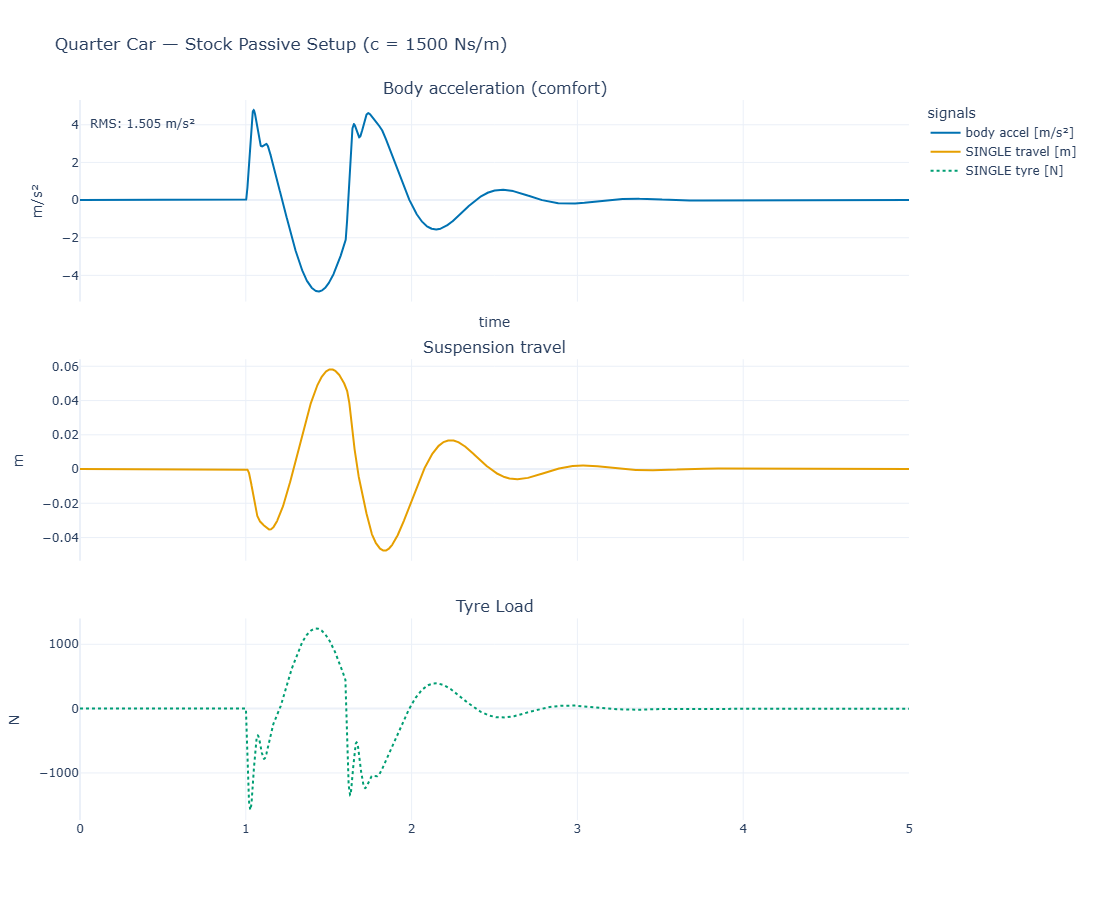

In [4]:
# Vehicle metrics plot for stock setup
stock_model  = QuarterCarModel(**BASE, damping=1500)
stock_result = simulate(stock_model, (0, 5), dt=0.001, inputs=road_bump)

fig = plot_vehicle_metrics(stock_result, model=stock_model)
fig.update_layout(title='Quarter Car — Stock Passive Setup (c = 1500 Ns/m)')
fig.show()
fig.write_image(str(IMG_DIR / 'qc_stock_passive.png'), width=1200, height=700, scale=2)

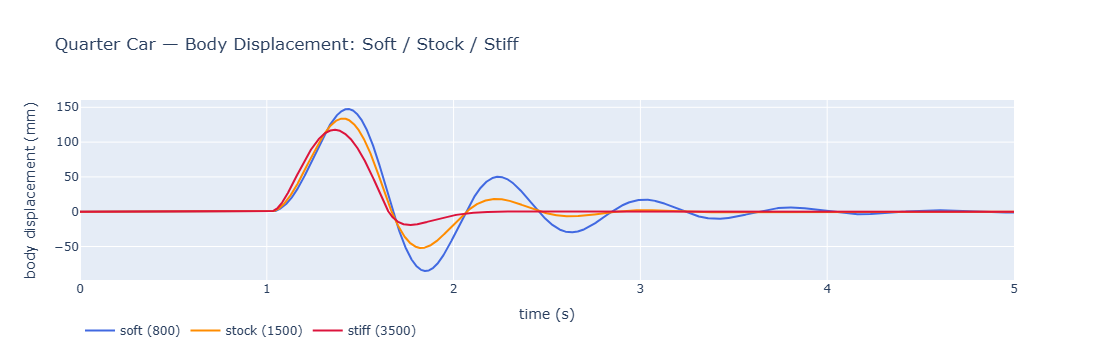

In [5]:
# Overlay body displacement for soft / stock / stiff
import plotly.graph_objects as go

colors = {'soft (800)': 'royalblue', 'stock (1500)': 'darkorange', 'stiff (3500)': 'crimson'}
fig2 = go.Figure()
for label, r in passive_results.items():
    fig2.add_trace(go.Scatter(
        x=r.time, y=r.state[:, 0] * 1000,
        mode='lines', name=label, line={'color': colors[label]},
    ))
fig2.update_layout(
    title='Quarter Car — Body Displacement: Soft / Stock / Stiff',
    xaxis_title='time (s)', yaxis_title='body displacement (mm)',
    legend={'orientation': 'h', 'y': -0.2},
)
fig2.show()
fig2.write_image(str(IMG_DIR / 'qc_damping_sweep.png'), width=1200, height=500, scale=2)

## 3  Active Control — Skyhook, Groundhook, Hybrid, Semi-active

SimWeave ships ready-made controller classes in `simweave.continuous.control`.
Pass them via the `controller=` argument — no subclassing needed.

In [6]:
C_SKY = 5_000.0   # active damping coefficient (Ns/m)
C_GROUND = 1_500.0
K_T = BASE['tyre_stiffness']

configs = [
    ('Passive',          QuarterCarModel(**BASE, damping=1500)),
    ('Skyhook',          QuarterCarModel(**BASE, damping=1500, controller=SkyhookDamper(C_SKY))),
    ('Groundhook',       QuarterCarModel(**BASE, damping=1500, controller=GroundhookDamper(C_GROUND))),
    ('Hybrid (α=0.5)',   QuarterCarModel(**BASE, damping=1500,
                            controller=HybridActiveDamper(C_SKY, C_GROUND, alpha=0.5))),
    ('Semi-active sky',  QuarterCarModel(**BASE, damping=1500,
                             controller=SemiActiveWrapper(SkyhookDamper(C_SKY)))),
]

ctrl_results = {}
print(f'{"Controller":20s}  {"RMS accel (m/s²)":>15s}  {"Peak tyre (mm)":>18s} {"RMS tyre load (N)":>21s}')
print('-' * 80)
for name, model in configs:
    r = simulate(model, (0, 5), dt=0.001, inputs=rough_bump)
    z_s_ddot = np.gradient(r.state[:, 1], r.time)
    # stu added
    z_u_ddot = np.gradient(r.state[:, 3], r.time)
    #tyre_force = z_u_ddot * BASE['unsprung_mass']
    tyre_force = K_T * r.state[:, 2]
    
    rms  = np.sqrt(np.mean(z_s_ddot**2))
    peak = np.max(np.abs(r.state[:, 2])) * 1000
    #rms_t = np.sqrt(np.mean(np.abs(tyre_force - np.mean(tyre_force))))
    rms_t   = np.sqrt(np.mean(tyre_force**2))
    print(f'{name:20s}  {rms:>15.3f}  {peak:>18.1f} {rms_t:>21.1f}')
    ctrl_results[name] = r

Controller            RMS accel (m/s²)      Peak tyre (mm)     RMS tyre load (N)
--------------------------------------------------------------------------------
Passive                         2.235                61.3                1613.0
Skyhook                         2.202                67.7                1760.4
Groundhook                      2.794                56.3                1421.7
Hybrid (α=0.5)                  2.500                62.9                1560.9
Semi-active sky                 2.349                62.8                1664.7


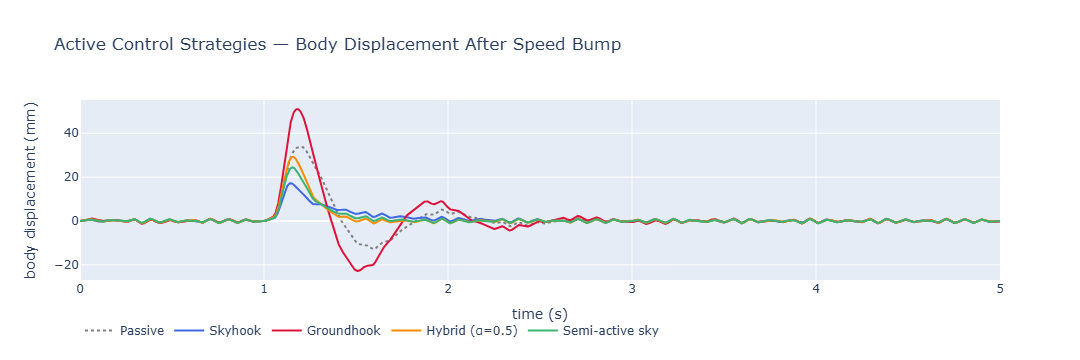

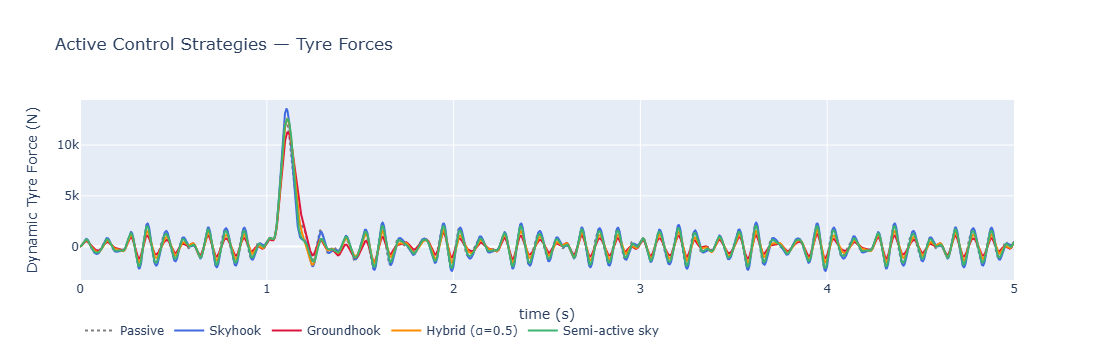

In [7]:
# Overlay body displacement for all controller strategies
palette = {
    'Passive':         'grey',
    'Skyhook':         'royalblue',
    'Groundhook':      'crimson',
    'Hybrid (α=0.5)':  'darkorange',
    'Semi-active sky': 'mediumseagreen',
}
fig3 = go.Figure()
for name, r in ctrl_results.items():
    fig3.add_trace(go.Scatter(
        x=r.time, y=r.state[:, 0] * 1000,
        mode='lines', name=name,
        line={'color': palette[name], 'dash': 'dot' if name == 'Passive' else 'solid'},
    ))
fig3.update_layout(
    title='Active Control Strategies — Body Displacement After Speed Bump',
    xaxis_title='time (s)', yaxis_title='body displacement (mm)',
    legend={'orientation': 'h', 'y': -0.2},
)
fig3.show()
fig3.write_image(str(IMG_DIR / 'qc_controllers.png'), width=1200, height=500, scale=2)


# show tyre loading
fig3b = go.Figure()
for name, r in ctrl_results.items():
    fig3b.add_trace(go.Scatter(
        x=r.time, y=K_T * r.state[:, 2],
        mode='lines', name=name,
        line={'color': palette[name], 'dash': 'dot' if name == 'Passive' else 'solid'},
    ))
fig3b.update_layout(
    title='Active Control Strategies — Tyre Forces',
    xaxis_title='time (s)', yaxis_title='Dynamic Tyre Force (N)',
    legend={'orientation': 'h', 'y': -0.2},
)
fig3b.show()
#fig3b.write_image(str(IMG_DIR / 'qc_controllers.png'), width=1200, height=500, scale=2)

## 4  Comfort–Handling Pareto Front

Sweep `alpha` from 0 (pure groundhook — best handling) to 1 (pure skyhook — best comfort)
to map out the achievable trade-off frontier.

Firstly sweep Skyhook and Groundhook separately to demonstrate optimal damping for each

In [8]:
# make a reusable function for sweeping parameters - note this may be embedded in future SimWeave releases please see the docs
def sweep_and_plot(
    sweep_values,
    controller_factory,
    sweep_label,
    title,
    xaxis_title,
    yaxis_title,
    colorbar_title,
    damping=1500,
    sim_time=(0, 5),
    dt=0.001,
):
    """
    Generic sweep + comfort/handling plotter.

    sweep_values: iterable of parameter values (e.g. damping, alpha)
    controller_factory: function(value) -> controller instance
    sweep_label: function(value) -> string for hover text
    """

    rms_accels = []
    peak_tyres = []

    for val in sweep_values:
        model = QuarterCarModel(
            **BASE,
            damping=damping,
            controller=controller_factory(val)
        )

        r = simulate(model, sim_time, dt=dt, inputs=rough_bump)

        # sprung mass acceleration
        z_s_ddot = np.gradient(r.state[:, 1], r.time)
        rms_accels.append(np.sqrt(np.mean(z_s_ddot**2)))

        # tyre force RMS
        tyre_force = K_T * r.state[:, 2]
        peak_tyres.append(np.sqrt(np.mean(tyre_force**2)))

    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=peak_tyres,
        y=rms_accels,
        mode='lines+markers',
        marker={
            'color': sweep_values,
            'colorscale': 'RdYlBu',
            'size': 8,
            'colorbar': {'title': colorbar_title},
        },
        text=[sweep_label(v) for v in sweep_values],
        hovertemplate='%{text}<br>Tyre: %{x:.1f} N<br>RMS: %{y:.3f} m/s²',
    ))

    fig.update_layout(
        title=title,
        xaxis_title=xaxis_title,
        yaxis_title=yaxis_title,
    )

    return fig


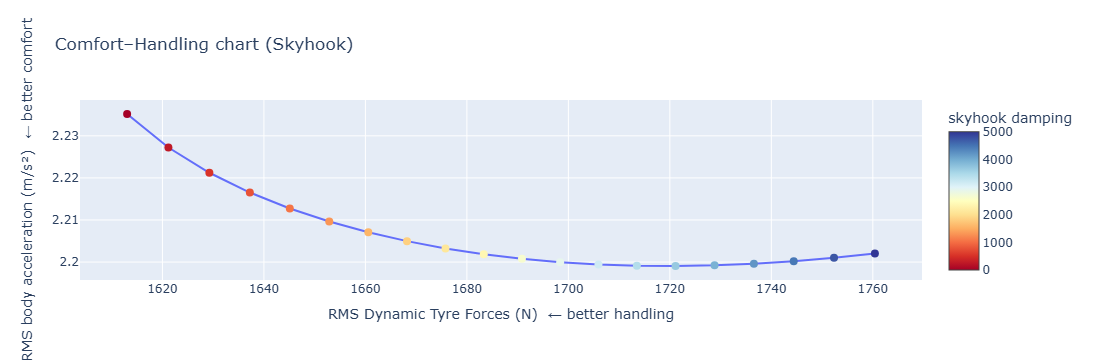

In [9]:
c_sky_range = np.linspace(0, 5000, 20)

fig4a = sweep_and_plot(
    sweep_values=c_sky_range,
    controller_factory=lambda c: SkyhookDamper(c),
    sweep_label=lambda c: f"damping={c:.2f}",
    title="Comfort–Handling chart (Skyhook)",
    xaxis_title="RMS Dynamic Tyre Forces (N)  ← better handling",
    yaxis_title="RMS body acceleration (m/s²)  ← better comfort",
    colorbar_title="skyhook damping",
)
fig4a.show()
fig4a.write_image(str(IMG_DIR / 'skyhook_pareto.png'), width=900, height=600, scale=2)

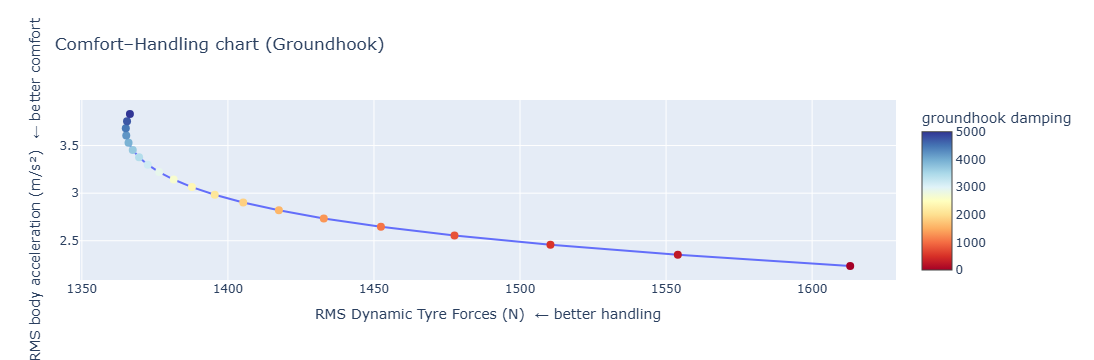

In [10]:
c_grd_range = np.linspace(0, 5000, 20)

fig4b = sweep_and_plot(
    sweep_values=c_grd_range,
    controller_factory=lambda c: GroundhookDamper(c),
    sweep_label=lambda c: f"damping={c:.2f}",
    title="Comfort–Handling chart (Groundhook)",
    xaxis_title="RMS Dynamic Tyre Forces (N)  ← better handling",
    yaxis_title="RMS body acceleration (m/s²)  ← better comfort",
    colorbar_title="groundhook damping",
)
fig4b.show()
fig4b.write_image(str(IMG_DIR / 'groundhook_pareto.png'), width=900, height=600, scale=2)


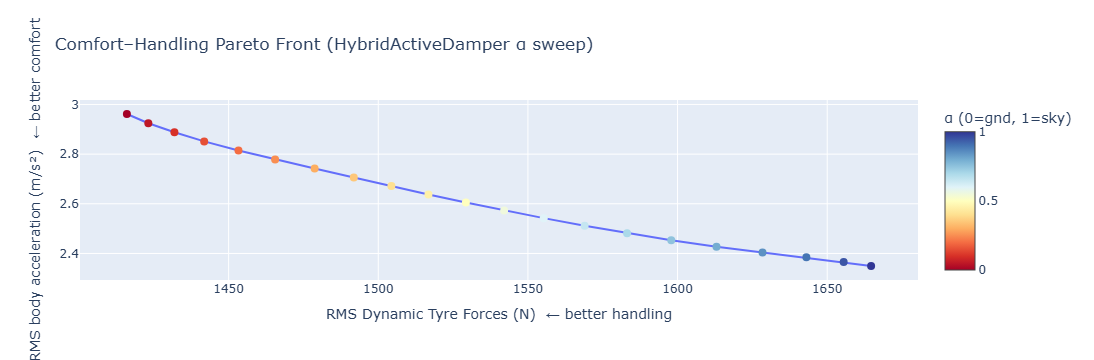

In [11]:
alphas = np.linspace(0, 1, 21)

fig4c = sweep_and_plot(
    sweep_values=alphas,
    controller_factory=lambda a: SemiActiveWrapper(
        HybridActiveDamper(5000, 2100, alpha=a)
    ),
    sweep_label=lambda a: f"α={a:.2f}",
    title="Comfort–Handling Pareto Front (HybridActiveDamper α sweep)",
    xaxis_title="RMS Dynamic Tyre Forces (N)  ← better handling",
    yaxis_title="RMS body acceleration (m/s²)  ← better comfort",
    colorbar_title="α (0=gnd, 1=sky)",
)
fig4c.show()
fig4c.write_image(str(IMG_DIR / 'hybrid_pareto.png'), width=900, height=600, scale=2)


## Overlay Pareto Plots

In [12]:
def overlay_sweeps(sweeps, title, xaxis_title, yaxis_title):
    fig = go.Figure()

    for sweep in sweeps:
        vals = sweep["values"]
        rms_accels = []
        peak_tyres = []

        for v in vals:
            model = QuarterCarModel(
                **BASE,
                damping=sweep.get("damping", 1500),
                controller=sweep["controller_factory"](v)
            )
            r = simulate(model, (0, 5), dt=0.001, inputs=rough_bump)

            z_s_ddot = np.gradient(r.state[:, 1], r.time)
            rms_accels.append(np.sqrt(np.mean(z_s_ddot**2)))

            tyre_force = K_T * r.state[:, 2]
            peak_tyres.append(np.sqrt(np.mean(tyre_force**2)))

        fig.add_trace(go.Scatter(
            x=peak_tyres,
            y=rms_accels,
            mode='lines+markers',
            name=sweep["name"],
            marker={
                "size": 8,
                "color": sweep.get("color", None),
            },
            text=[sweep["label"](v) for v in vals],
            hovertemplate='%{text}<br>Tyre: %{x:.1f} N<br>RMS: %{y:.3f} m/s²',
        ))

    fig.update_layout(
        title=title,
        xaxis_title=xaxis_title,
        yaxis_title=yaxis_title,
    )
    return fig


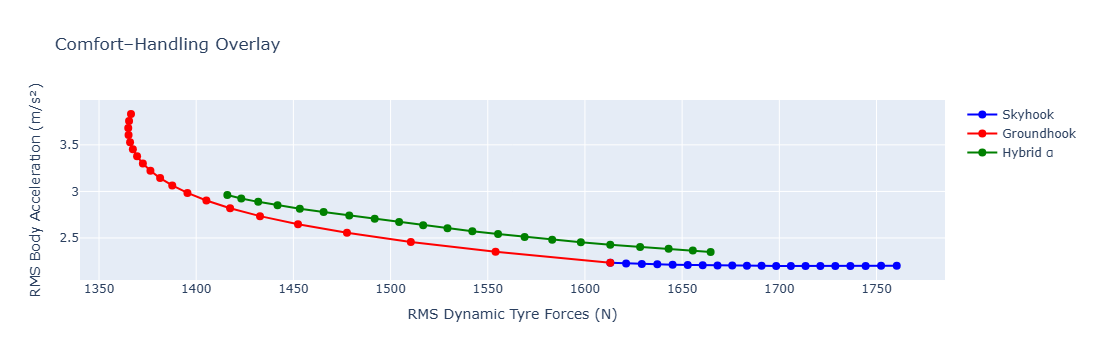

In [13]:
fig_overlay = overlay_sweeps(
    sweeps=[
        {
            "name": "Skyhook",
            "values": np.linspace(0, 5000, 20),
            "controller_factory": lambda c: SkyhookDamper(c),
            "label": lambda c: f"Skyhook c={c:.0f}",
            "color": "blue",
        },
        {
            "name": "Groundhook",
            "values": np.linspace(0, 5000, 20),
            "controller_factory": lambda c: GroundhookDamper(c),
            "label": lambda c: f"Groundhook c={c:.0f}",
            "color": "red",
        },
        {
            "name": "Hybrid α",
            "values": np.linspace(0, 1, 21),
            "controller_factory": lambda a: SemiActiveWrapper(
                HybridActiveDamper(5000, 2100, alpha=a)
            ),
            "label": lambda a: f"α={a:.2f}",
            "color": "green",
        },
    ],
    title="Comfort–Handling Overlay",
    xaxis_title="RMS Dynamic Tyre Forces (N)",
    yaxis_title="RMS Body Acceleration (m/s²)",
)

fig_overlay.show()
fig_overlay.write_image(str(IMG_DIR / 'overlay_pareto.png'), width=900, height=600, scale=2)

## 5  Half Car and Full Car Models

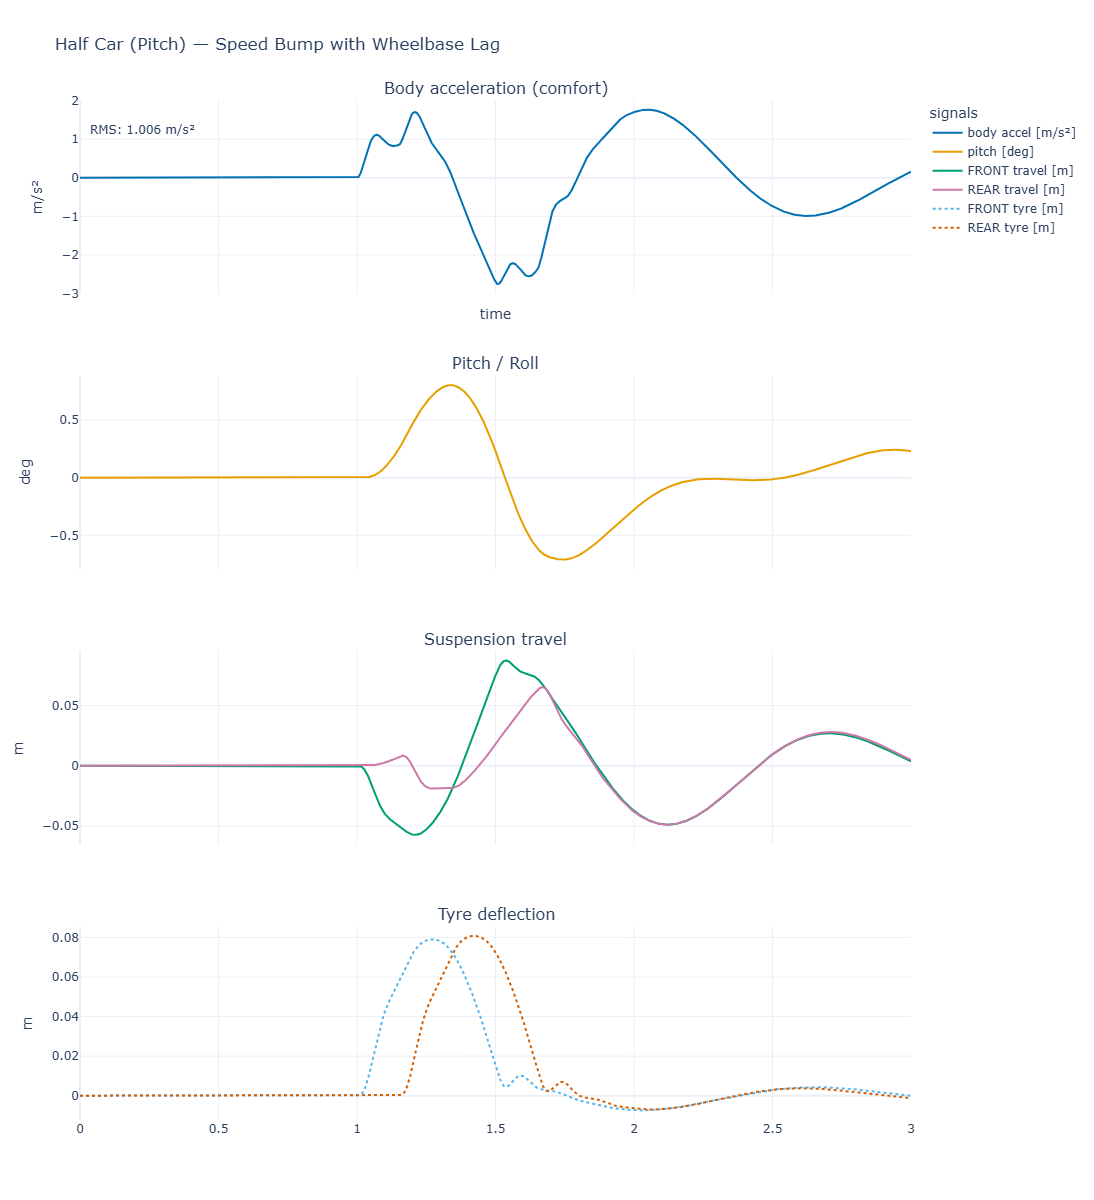

In [14]:
# Half car (pitch) — front and rear wheel hit the same bump with a time lag
def road_pair(t):
    def bump(t0):
        if t0 < t < t0 + 0.5:
            return 0.08 * np.sin(np.pi * (t - t0) / 0.5)
        return 0.0
    return bump(1.0), bump(1.15)   # front, rear

hc_model = HalfCarModel(
        sprung_mass=1200.0,
        pitch_inertia=2500.0,
        unsprung_mass_front=60.0,
        unsprung_mass_rear=60.0,
        k_sf=20000.0,
        k_sr=20000.0,
        c_sf=1500.0,
        c_sr=1500.0,
        k_tf=150000.0,
        k_tr=150000.0,
        a=1.2,
        b=1.6,
    )

hc_result = simulate(
        hc_model,
        (0.0, 3.0),
        dt=0.001,
        inputs=road_pair,
    )

fig5 = plot_vehicle_metrics(hc_result, model=hc_model)
fig5.update_layout(title='Half Car (Pitch) — Speed Bump with Wheelbase Lag')
fig5.show()
fig5.write_image(str(IMG_DIR / 'half_car_pitch.png'), width=1200, height=700, scale=2)

Peak heave : 0.02203467398663131 [m]
Peak pitch : 0.013972205798768672 [rad]
Peak roll  : 0.02597579260381035 [rad]


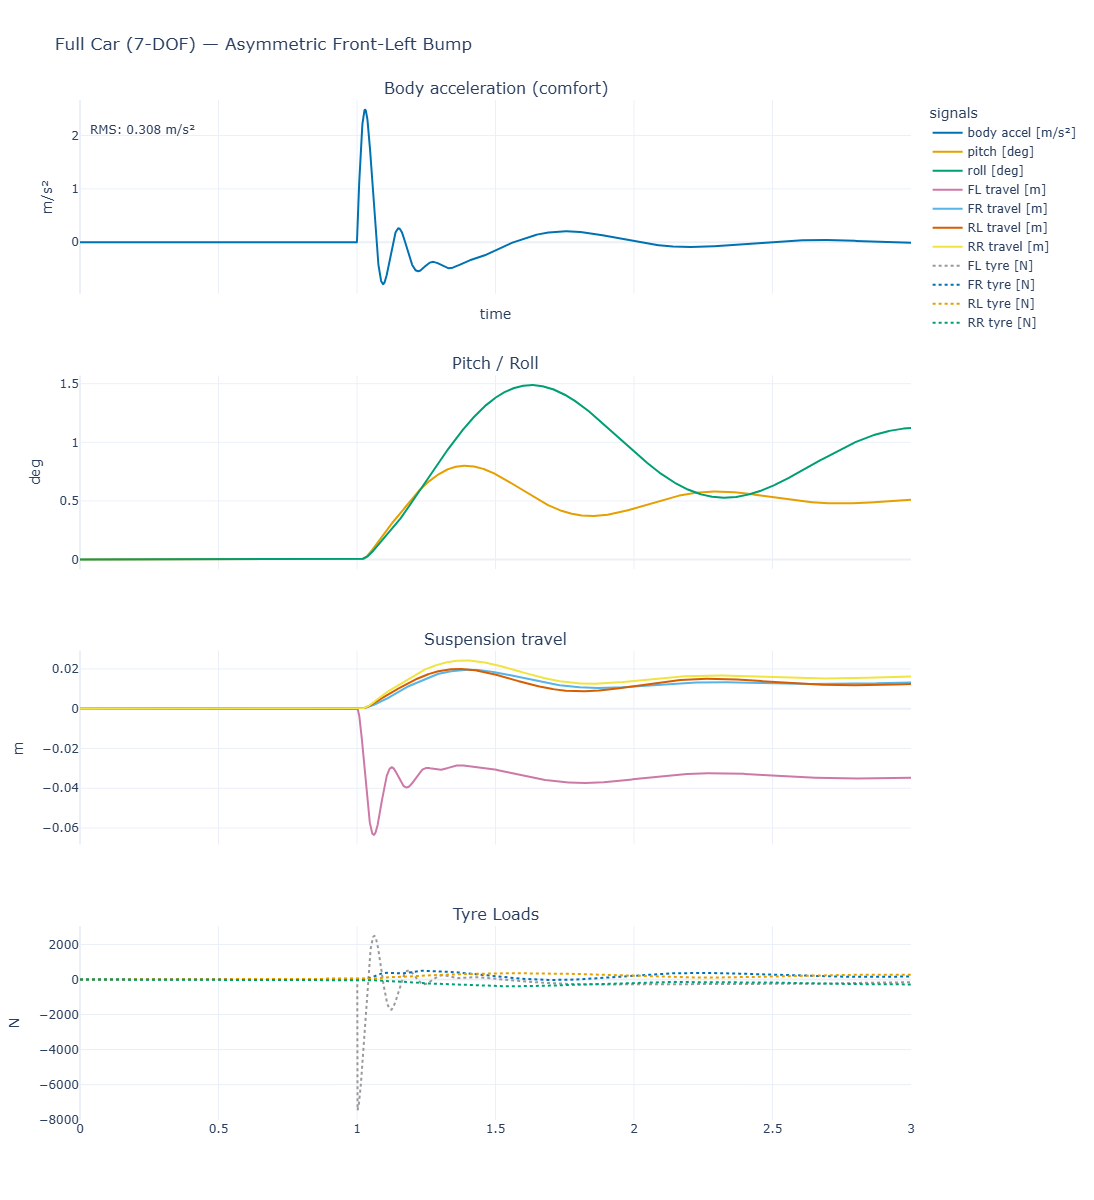

In [15]:
# Full car (7-DOF) — asymmetric bump on front-left only
def asymmetric_bump(t):
    fl = 0.05 if t > 1.0 else 0.0
    return (fl, 0.0, 0.0, 0.0)   # FL, FR, RL, RR

fc_model = FullCarModel(
        sprung_mass=1200,
        pitch_inertia=2500,
        roll_inertia=2200,
        unsprung_mass=60,
        k_s=20000,
        c_s=1500,
        k_t=150000,
        a=1.2, # CG → front axle
        b=1.6, # CG → rear axle
        track_width=1.6
    )

fc_result = simulate(fc_model, (0, 3), dt=0.001, inputs=asymmetric_bump)

# Wrap states into typed SI quantities
typed = fc_model.wrap_states(fc_result)
print('Peak heave :', typed['z_s'].max())
print('Peak pitch :', typed['theta'].max())
print('Peak roll  :', typed['phi'].max())

fig6 = plot_vehicle_metrics(fc_result, model=fc_model)
fig6.update_layout(title='Full Car (7-DOF) — Asymmetric Front-Left Bump')
fig6.show()
fig6.write_image(str(IMG_DIR / 'full_car.png'), width=1200, height=700, scale=2)

## Summary — Exported Images for Medium

All key figures have been saved to the `img/` folder:

| File | Description |
|---|---|
| `qc_stock_passive.png` | Multi-panel vehicle metrics for stock passive setup |
| `qc_damping_sweep.png` | Body displacement — soft / stock / stiff comparison |
| `qc_controllers.png` | Active control strategy comparison |
| `qc_pareto.png` | Comfort–handling Pareto front |
| `half_car_pitch.png` | Half car pitch response |
| `full_car.png` | Full car 7-DOF asymmetric bump response |